In [3]:
%pip install -q "transformers==4.57.1" "accelerate==1.11.0" pillow pandas requests pyarrow

In [2]:
from google.colab import drive
drive.mount("/content/drive")

Mounted at /content/drive


In [4]:
import json
import math
import re
from pathlib import Path

import requests
import torch
import pandas as pd
from PIL import Image, ImageDraw
from IPython.display import display
from tqdm.auto import tqdm
from transformers import (
    AutoProcessor, GenerationConfig,
    Qwen3VLForConditionalGeneration
)

In [5]:
ROOT = Path("/content/drive/MyDrive/MLLM/mordern_llm")
DATA = ROOT / "data/grounding20"
IMAGES = DATA / "images"
OUTPUTS = ROOT / "outputs/grounding"
MODEL_ID = "Qwen/Qwen3-VL-2B-Instruct"

IMAGES.mkdir(parents=True, exist_ok=True)
OUTPUTS.mkdir(parents=True, exist_ok=True)

dtype = torch.bfloat16 if torch.cuda.is_bf16_supported() else torch.float16

processor = AutoProcessor.from_pretrained(MODEL_ID, use_fast=False)

model = Qwen3VLForConditionalGeneration.from_pretrained(
    MODEL_ID,
    dtype=dtype,
    device_map="auto",
    attn_implementation="sdpa"
).eval()

GEN = GenerationConfig(
    max_new_tokens=64,
    do_sample=False,
    bos_token_id=model.generation_config.bos_token_id,
    eos_token_id=model.generation_config.eos_token_id,
    pad_token_id=processor.tokenizer.pad_token_id
)

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:104: UserWarning: 
Error while fetching `HF_TOKEN` secret value from your vault: 'Requesting secret HF_TOKEN timed out. Secrets can only be fetched when running from the Colab UI.'.
You are not authenticated with the Hugging Face Hub in this notebook.
If the error persists, please let us know by opening an issue on GitHub (https://github.com/huggingface/huggingface_hub/issues/new).
  warnings.warn(


preprocessor_config.json:   0%|          | 0.00/390 [00:00<?, ?B/s]

tokenizer_config.json: 0.00B [00:00, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

...

video_preprocessor_config.json:   0%|          | 0.00/385 [00:00<?, ?B/s]

chat_template.json: 0.00B [00:00, ?B/s]

config.json: 0.00B [00:00, ?B/s]

model.safetensors:   0%|          | 0.00/4.26G [00:00<?, ?B/s]

generation_config.json:   0%|          | 0.00/269 [00:00<?, ?B/s]

In [6]:
source_path = DATA / "source_rows.json"

if not source_path.exists():
    response = requests.get(
        "https://datasets-server.huggingface.co/rows",
        params={
            "dataset": "lmms-lab-encoder/RefCOCO",
            "config": "default",
            "split": "val",
            "offset": 0,
            "length": 20
        },
        timeout=30
    )
    response.raise_for_status()
    source_path.write_text(
        json.dumps(response.json(), ensure_ascii=False, indent=2),
        encoding="utf-8"
    )

source = json.loads(source_path.read_text(encoding="utf-8"))
print(len(source))

5


In [7]:
examples = []
for item in source["rows"]:
    row = item["row"]
    match = re.match(
        r"(COCO_(train2014|val2014)_\d{12})",
        row["file_name"]   
    )
    
    filename = match.group(1) + ".jpg"
    split_folder = match.group(2)
    image_path = IMAGES / filename
    
    if not image_path.exists():
        url = f"http://images.cocodataset.org/{split_folder}/{filename}"
        response = requests.get(url, timeout=30)
        response.raise_for_status()
        image_path.write_bytes(response.content)
    
    with Image.open(image_path) as image:
        width, height = image.size
    
    x, y, w, h = map(float, row["bbox"])
    examples.append({
        "id": row["question_id"],
        "phrase": row["answer"][0],
        "image_path": str(image_path),
        "width": width,
        "height": height,
        "gt_xyxy": [x, y, x + w, y + h],
    })

(DATA / "manifest.json").write_text(
    json.dumps(examples, ensure_ascii=False, indent=2),
    encoding="utf-8"
)

print("Examples:", len(examples))
print("Unique images:", len({e["image_path"] for e in examples}))
print("First phrase:", examples[0]["phrase"])

Examples: 20
Unique images: 9
First phrase: bowl behind the others can only see part


**Parser, coordinate conversion and IoU**

In [8]:
def parse_box(raw):
    text = raw.strip()
    lines = text.splitlines()
    wrapped = (
        len(lines) >= 3
        and lines[0].strip().lower() in ("```json", "```")
        and lines[-1].strip() == "```"
    )
    
    if wrapped:
        text = "\n".join(lines[1:-1]).strip()
    
    obj = json.loads(text)
    if not (isinstance(obj, list) and len(obj) == 1 and isinstance(obj[0], dict)):
        raise ValueError("Expected one object in a JSON array")
    
    box = obj[0].get("bbox_2d")
    if not (isinstance(box, list) and len(box) == 4):
        raise ValueError("Expected four coordinates")

    if not all(
        type(v) in (int, float) and math.isfinite(v)
        and 0 <= v <= 1000 for v in box
    ):
        raise ValueError("Coordinates must be finite numbers in 0..1000")
    
    x1, y1, x2, y2 = map(float, box)
    if not (x1 < x2 and y1 < y2):
        raise ValueError("Invalid xyxy order or zero area")

    return [x1, y1, x2, y2], wrapped

In [9]:
def to_pixels(box, width, height):
    return [
        box[0] * width / 1000,
        box[1] * height / 1000,
        box[2] * width / 1000,
        box[3] * height / 1000,
    ]

def box_iou(a, b):
    iw = max(0, min(a[2], b[2]) - max(a[0], b[0]))
    ih = max(0, min(a[3], b[3]) - max(a[1], b[1]))
    intersection = iw * ih
    
    area_a = (a[2] - a[0]) * (a[3] - a[1])
    area_b = (b[2] - b[0]) * (b[3] - b[1])

    return intersection / (area_a + area_b - intersection)

**Inference**

In [10]:
@torch.inference_mode()
def ground(image_path, phrase):
    with Image.open(image_path) as source:
        image = source.convert("RGB")
        
    question = (
        f"Locate the single object described by: {phrase!r}. "
        'Return a JSON array containing exactly one object: '
        '[{"bbox_2d": [x1, y1, x2, y2]}]. '
        "Use xyxy coordinates normalized to 0..1000 "
        "relative to the whole image. "
        "Output only JSON, without markdown or explanation."
    )
    messages = [{
        "role": "user",
        "content": [
            {"type": "image"},
            {"type": "text", "text": question},
        ],
    }]
    
    prompt = processor.apply_chat_template(
        messages, tokenize=False, add_generation_prompt=True
    )

    batch = processor(
        text=[prompt],
        images=[image],
        images_kwargs={
            "do_resize": True,
            "min_pixels": 64 * 32 * 32,
            "max_pixels": 400 * 32 * 32,
        },
        return_tensors="pt"
    ).to(model.device)
    
    output = model.generate(
        **batch,
        generation_config=GEN,
        use_model_defaults=False,
        do_sample=False,
    )

    new_ids = output[:, batch["input_ids"].shape[1]:]
    return processor.batch_decode(
        new_ids,
        skip_special_tokens=True,
        clean_up_tokenization_spaces=False,
    )[0]

In [11]:
def evaluate_example(example):
    raw = ground(example["image_path"], example["phrase"])
    
    try:
        normalized_box, wrapped = parse_box(raw)
        prediction = to_pixels(
            normalized_box, example["width"], example["height"]
        )
        iou = box_iou(prediction, example["gt_xyxy"])
        error = None
    
    except ValueError as exc:
        prediction = None
        iou = 0.0
        wrapped = False
        error = str(exc)
    
    return {
        **example,
        "raw_answer": raw,
        "pred_xyxy": prediction,
        "used_fence_cleanup": wrapped,
        "box_valid": prediction is not None,
        "iou": iou,
        "success": prediction is not None and iou >= 0.5,
        "error": error
    }

first_result = evaluate_example(examples[0])

print("Phrase:", first_result["phrase"])
print("Raw answer:", first_result["raw_answer"])
print("Pixel prediction:", first_result["pred_xyxy"])
print("IoU:", round(first_result["iou"], 3))

Phrase: bowl behind the others can only see part
Raw answer: ```json
[
	{"bbox_2d": [183, 0, 720, 424], "label": "bowl behind the others can only see part"}
]
```
Pixel prediction: [117.12, 0.0, 460.8, 181.472]
IoU: 0.0


**Original image GT**

Phrase: bowl behind the others can only see part
IoU: 0.000 | Success: False
Green = GT | Red = prediction


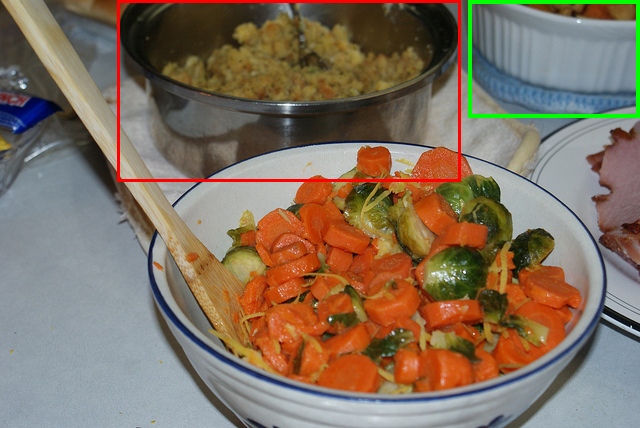

In [12]:
def show_case(result):
    with Image.open(result["image_path"]) as source:
        canvas = source.convert("RGB")
    
    draw = ImageDraw.Draw(canvas)
    draw.rectangle(
        result["gt_xyxy"], outline="lime", width=4
    )
    
    if result["pred_xyxy"] is not None:
        draw.rectangle(
            result["pred_xyxy"], outline="red", width=3
        )
    
    print("Phrase:", result["phrase"])
    print(
        f"IoU: {result['iou']:.3f} | "
        f"Success: {result['success']}"
    )
    print("Green = GT | Red = prediction")
    if result["error"]:
        print("Output error:", result["error"])

    display(canvas)
    canvas.save(OUTPUTS / f"{result['id']}_overlay.png")


show_case(first_result)

**Evaluation and saving**

In [13]:
results = [first_result]
predictions_path = OUTPUTS / "day1_predictions.json"

for example in tqdm(examples[1:]):
    results.append(evaluate_example(example))

    predictions_path.write_text(
        json.dumps(results, ensure_ascii=False, indent=2),
        encoding="utf-8"
    )

df = pd.DataFrame(results)

summary = pd.DataFrame([{
    "queries": len(df),
    "usable_box_pct": 100 * df["box_valid"].mean(),
    "success_at_iou_0.5_pct": 100 * df["success"].mean(),
    "mean_iou_all_queries": df["iou"].mean(),
    "invalid_outputs": int((~df["box_valid"]).sum())
}])

display(
    df[["id", "phrase", "box_valid", "iou", "success"]].round(3)
)

display(summary.round(3))
summary.to_csv(OUTPUTS / "day1_metrics.csv", index=False)

  0%|          | 0/19 [00:00<?, ?it/s]

,id,phrase,box_valid,iou,success
0,1537681,bowl behind the others can only see part,True,0.000,False
1,710706,front bowl w/carrots in it,True,0.957,True
2,480908,little girl,True,0.947,True
3,469475,green woman,True,0.963,True
4,1746473,mom,True,0.934,True
5,1741008,child sitting on womans lap,True,0.875,True
6,190137,left guy,True,0.860,True
7,514243,lady on right,True,0.882,True
8,2159030,bottom box left dude,True,0.912,True
9,507653,Woman in top picture on the left.,True,0.897,True


,queries,usable_box_pct,success_at_iou_0.5_pct,mean_iou_all_queries,invalid_outputs
0,20,100.0,95.0,0.877,0


Phrase: bowl behind the others can only see part
IoU: 0.000 | Success: False
Green = GT | Red = prediction


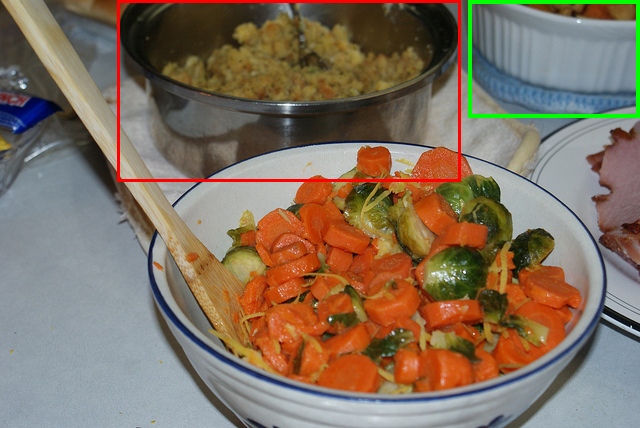

Raw answer: ```json
[
	{"bbox_2d": [183, 0, 720, 424], "label": "bowl behind the others can only see part"}
]
```


In [14]:
failed_cases = [
    result for result in results
    if not result["success"]
]

for result in failed_cases[:3]:
    show_case(result)
    print("Raw answer:", result["raw_answer"])

**Receipt Extraction Baseline and Training Data**

In [15]:
import hashlib
import random
import re
import time
import unicodedata
from collections import defaultdict
from decimal import Decimal

import pyarrow.parquet as pq
import transformers
from huggingface_hub import hf_hub_download

DOC_DIR = ROOT / "data/sroie"
DOC_IMAGES = DOC_DIR / "images"
DOC_OUT = ROOT / "outputs/documents"

FIELDS = ("company", "date", "total")
DATASET_ID = "jsdnrs/ICDAR2019-SROIE"
REVISION = "bffe40c26759f3376ec2b3ae9031dbba54cd587c"

DOC_IMAGES.mkdir(parents=True, exist_ok=True)
DOC_OUT.mkdir(parents=True, exist_ok=True)